# movies_meta

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.stats.mstats import winsorize
import missingno as msno
from pyampute.exploration.mcar_statistical_tests import MCARTest
from mpl_toolkits.mplot3d import Axes3D
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy import stats



In [4]:

# Load dataset
df = pd.read_csv("movies_metadata.csv")
#Overview

print("\n head data ")
display(df.head())

print("\n shape")
print(df.shape)


print("\n info")
df.info()

print("\n describe statistics")
display(df.describe())

print("\n missing values column")
print(df.isnull().sum())

print("\n total missing values")
print(df.isnull().sum().sum())

print("\n duplicated rows")
print(df.duplicated().sum())

print("\n Unique values  column")
print(df.nunique())



 head data 


C:\Users\HHC\AppData\Local\Temp\ipykernel_8172\979051443.py:2: DtypeWarning: Columns (0: popularity) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("movies_metadata.csv")


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0



 shape
(45466, 24)

 info
<class 'pandas.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  str    
 1   belongs_to_collection  4494 non-null   str    
 2   budget                 45466 non-null  str    
 3   genres                 45466 non-null  str    
 4   homepage               7782 non-null   str    
 5   id                     45466 non-null  str    
 6   imdb_id                45449 non-null  str    
 7   original_language      45455 non-null  str    
 8   original_title         45466 non-null  str    
 9   overview               44512 non-null  str    
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  str    
 12  production_companies   45463 non-null  str    
 13  production_countries   45463 non-null  str    
 14  release_date           45379 non-null 

,revenue,runtime,vote_average,vote_count
count,4.546000e+04,45203.000000,45460.000000,45460.000000
mean,1.120935e+07,94.128199,5.618207,109.897338
std,6.433225e+07,38.407810,1.924216,491.310374
min,0.000000e+00,0.000000,0.000000,0.000000
25%,0.000000e+00,85.000000,5.000000,3.000000
50%,0.000000e+00,95.000000,6.000000,10.000000
75%,0.000000e+00,107.000000,6.800000,34.000000
max,2.787965e+09,1256.000000,10.000000,14075.000000



 missing values column
adult                        0
belongs_to_collection    40972
budget                       0
genres                       0
homepage                 37684
id                           0
imdb_id                     17
original_language           11
original_title               0
overview                   954
popularity                   5
poster_path                386
production_companies         3
production_countries         3
release_date                87
revenue                      6
runtime                    263
spoken_languages             6
status                      87
tagline                  25054
title                        6
video                        6
vote_average                 6
vote_count                   6
dtype: int64

 total missing values
105562

 duplicated rows
13

 Unique values  column
adult                        5
belongs_to_collection     1698
budget                    1226
genres                    4069
homepage            

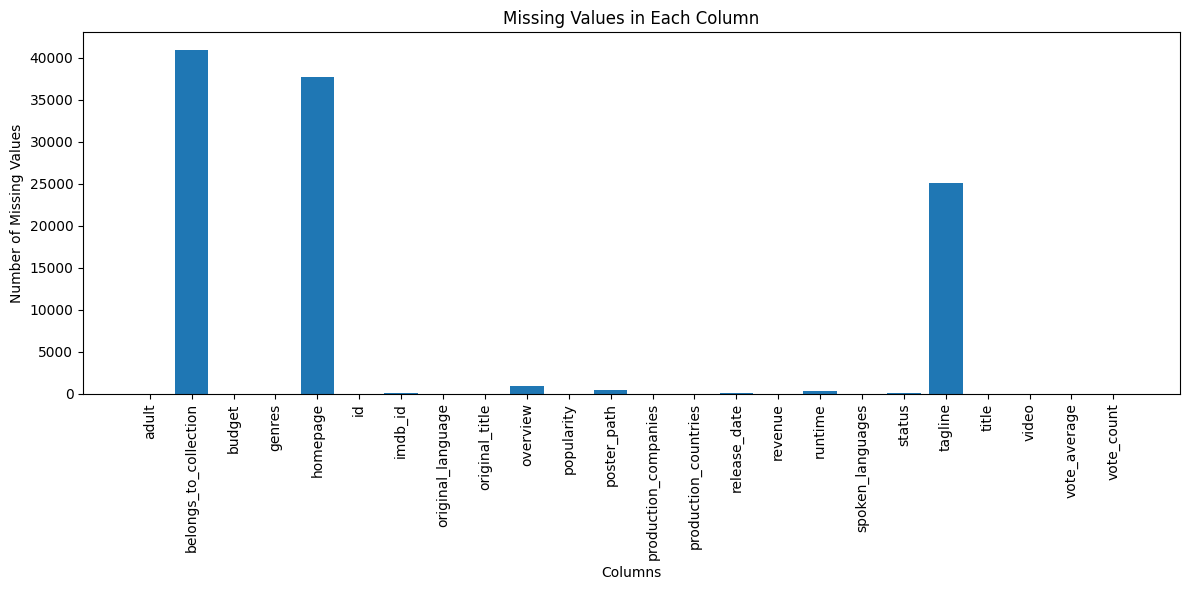

In [5]:

missing_values = {
    "adult": 0,
    "belongs_to_collection": 40972,
    "budget": 0,
    "genres": 0,
    "homepage": 37684,
    "id": 0,
    "imdb_id": 17,
    "original_language": 11,
    "original_title": 0,
    "overview": 954,
    "popularity": 5,
    "poster_path": 386,
    "production_companies": 3,
    "production_countries": 3,
    "release_date": 87,
    "revenue": 6,
    "runtime": 263,
    "spoken_languages": 6,
    "status": 87,
    "tagline": 25054,
    "title": 6,
    "video": 6,
    "vote_average": 6,
    "vote_count": 6
}

df_missing = pd.DataFrame(list(missing_values.items()), columns=["Column", "Missing Values"])

plt.figure(figsize=(12,6))
plt.bar(df_missing["Column"], df_missing["Missing Values"])
plt.xticks(rotation=90)
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values in Each Column")
plt.tight_layout()
plt.show()


In [6]:
# remove duplicated rows 
df = df.drop_duplicates()
print("duplicated rows after remove:",df.duplicated().sum() )


duplicated rows after remove: 0


- work with numeric feature

In numeric columns, the original missing values ​​were removed
because the missing data analysis in this project focuses on hidden missing values ​​(I mean, these values ​​are displayed as zeros in some selected columns.)

In [7]:
numeric_cols= ['budget','revenue','runtime','vote_average','vote_count','popularity']
df= df[numeric_cols]
df['budget'] = pd.to_numeric(df['budget'], errors='coerce')
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')

df = df.dropna()
df.info()
df.describe()


<class 'pandas.DataFrame'>
Index: 45190 entries, 0 to 45465
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   budget        45190 non-null  float64
 1   revenue       45190 non-null  float64
 2   runtime       45190 non-null  float64
 3   vote_average  45190 non-null  float64
 4   vote_count    45190 non-null  float64
 5   popularity    45190 non-null  float64
dtypes: float64(6)
memory usage: 2.4 MB


,budget,revenue,runtime,vote_average,vote_count,popularity
count,4.519000e+04,4.519000e+04,45190.000000,45190.000000,45190.000000,45190.000000
mean,4.249623e+06,1.127623e+07,94.124696,5.629363,110.527727,2.936888
std,1.747365e+07,6.451831e+07,38.411790,1.908886,492.706373,6.019567
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,0.000000e+00,0.000000e+00,85.000000,5.000000,3.000000,0.394017
50%,0.000000e+00,0.000000e+00,95.000000,6.000000,10.000000,1.135799
75%,0.000000e+00,0.000000e+00,107.000000,6.800000,34.000000,3.720080
max,3.800000e+08,2.787965e+09,1256.000000,10.000000,14075.000000,547.488298


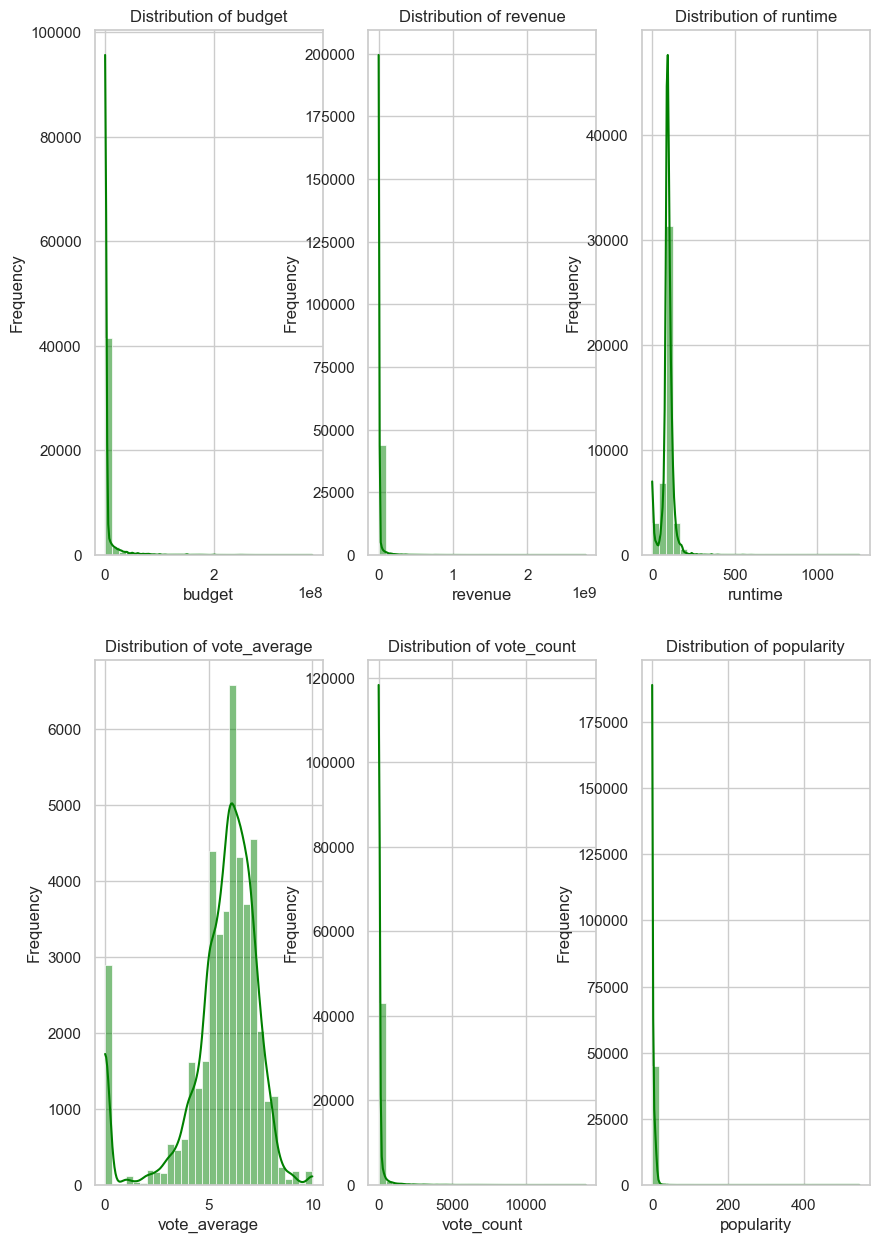

In [8]:
# draw 6 histogram chart for numeric colmns 
plt.figure(figsize=(10,15))

sns.set_theme(style="whitegrid", palette="pastel")
for i, col in enumerate(numeric_cols,1):
    plt.subplot(2,3,i)
    sns.histplot(df[col], bins=30, kde=True, color='green')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

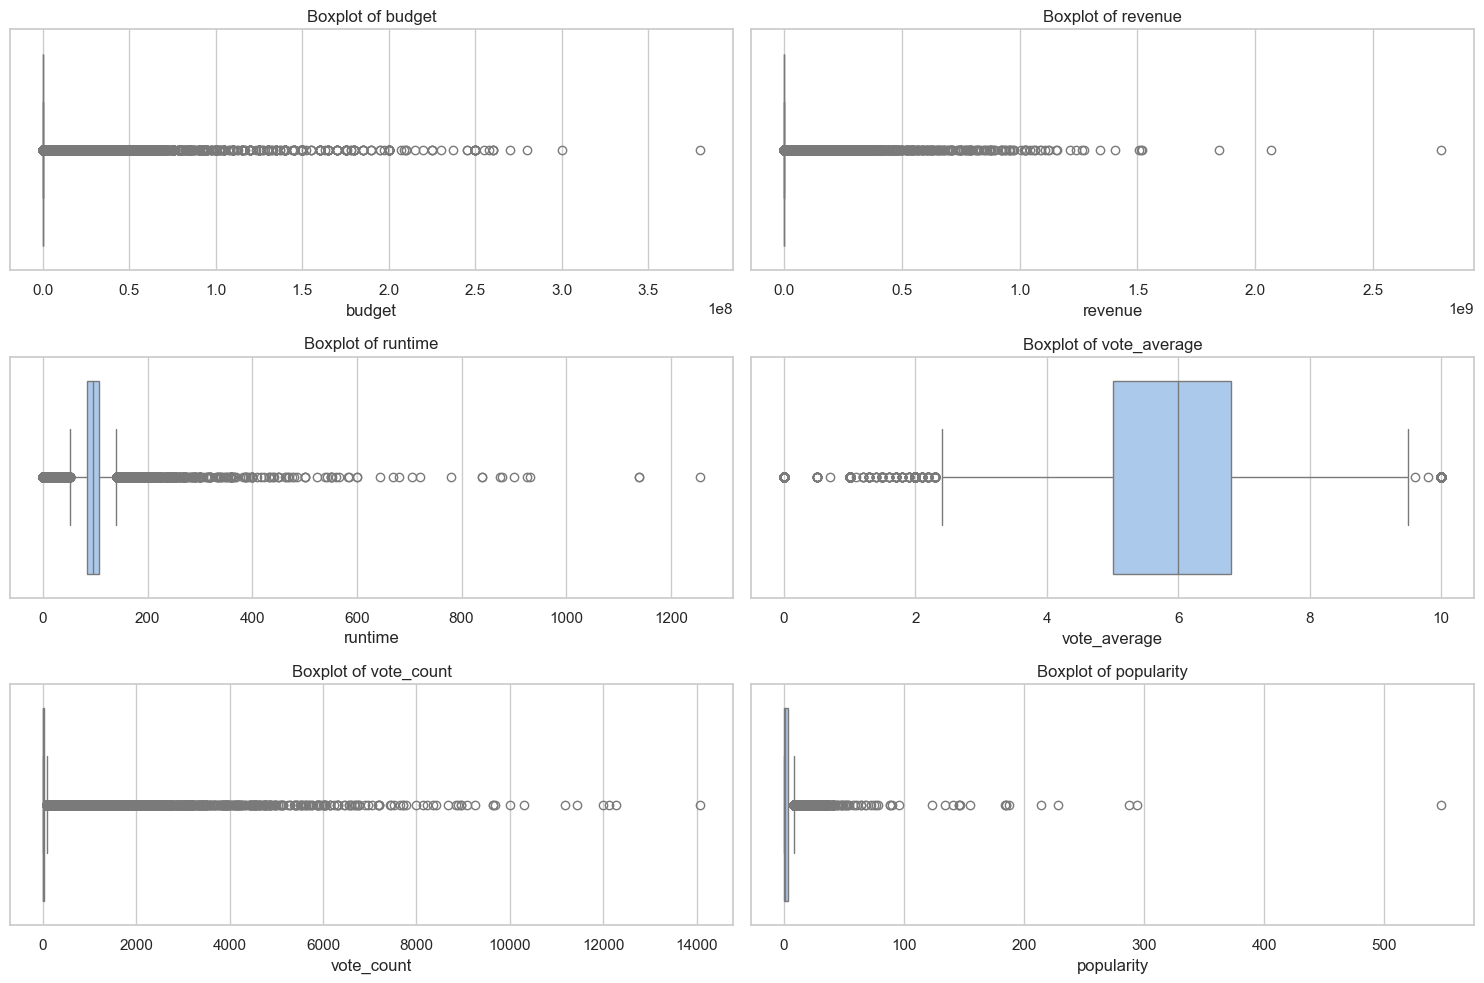

In [9]:
# drow boxplot for numeric colmns 
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()


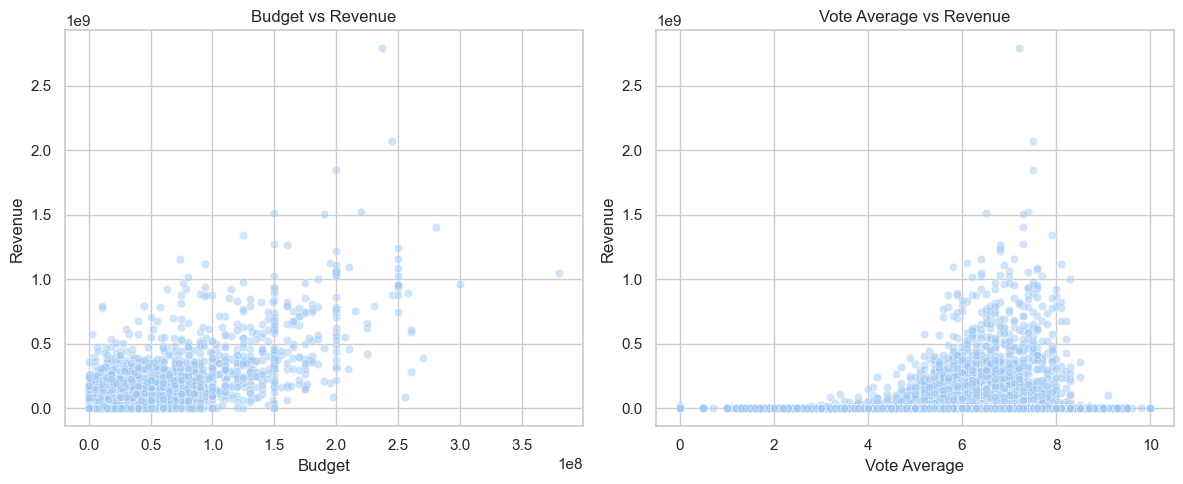

In [10]:
plt.figure(figsize=(12,5))
#drow scatterplot 
# Budget vs Revenue
plt.subplot(1,2,1)
sns.scatterplot(data=df, x='budget', y='revenue', alpha=0.5)
plt.title('Budget vs Revenue')
plt.xlabel('Budget')
plt.ylabel('Revenue')

# vote Average vs Revenue
plt.subplot(1,2,2)
sns.scatterplot(data=df, x='vote_average', y='revenue', alpha=0.5)
plt.title('Vote Average vs Revenue')
plt.xlabel('Vote Average')
plt.ylabel('Revenue')

plt.tight_layout()
plt.show()


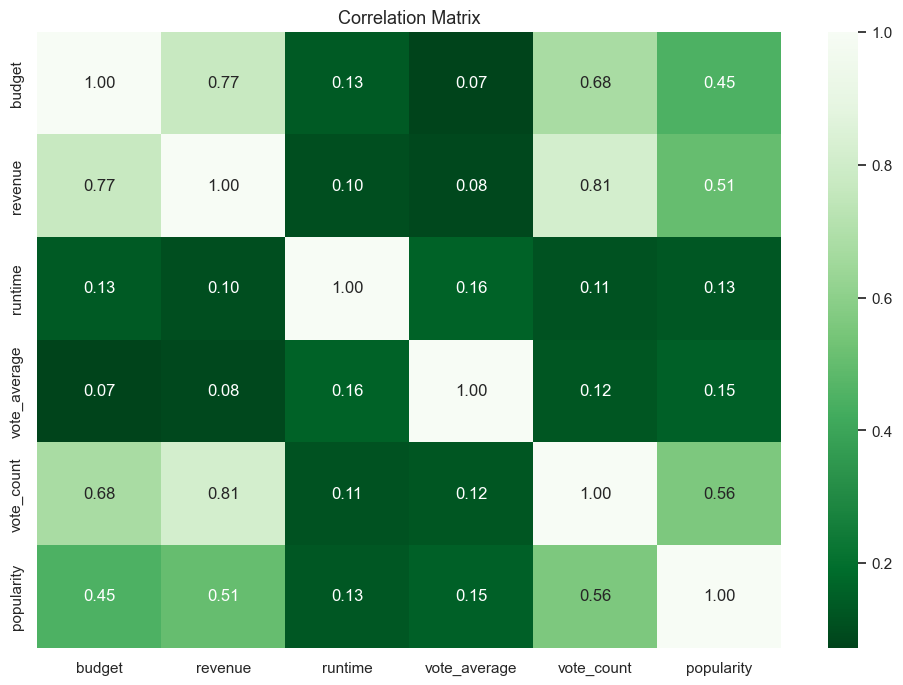

In [11]:

corr = df[numeric_cols].corr()

plt.figure(figsize=(12,8))

sns.heatmap(corr, annot=True, cmap='Greens_r', fmt=".2f")

plt.title('Correlation Matrix',size = 13)

plt.show()


# finaly after an overview, we use the Solution to missing data  

In [12]:

df_raw = df.copy()
df_log = df.copy()
df_missing = df.copy()
df_cluster = df.copy()
df_clean = df.copy()


We will work with numeric columns first because we currently need numeric columns given the form of the question.

- first solution: Remove zeros in numeric columns

In [13]:
zero_counts = (df_raw[numeric_cols] == 0).sum()

print("Number of zeros in numeric columns:\n")
print(zero_counts)
zero_percent = ((df_raw[numeric_cols] == 0).sum() / len(df)) * 100

print("\nPercentage of zeros in numeric columns:\n")
print(round(zero_percent, 2))



Number of zeros in numeric columns:

budget          36311
revenue         37790
runtime          1558
vote_average     2898
vote_count       2799
popularity         60
dtype: int64

Percentage of zeros in numeric columns:

budget          80.35
revenue         83.62
runtime          3.45
vote_average     6.41
vote_count       6.19
popularity       0.13
dtype: float64


C:\Users\HHC\AppData\Local\Temp\ipykernel_8172\3327145710.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=zero_counts.index, y=zero_counts.values, palette="viridis")
C:\Users\HHC\AppData\Local\Temp\ipykernel_8172\3327145710.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=zero_percent.index, y=zero_percent.values, palette="viridis")


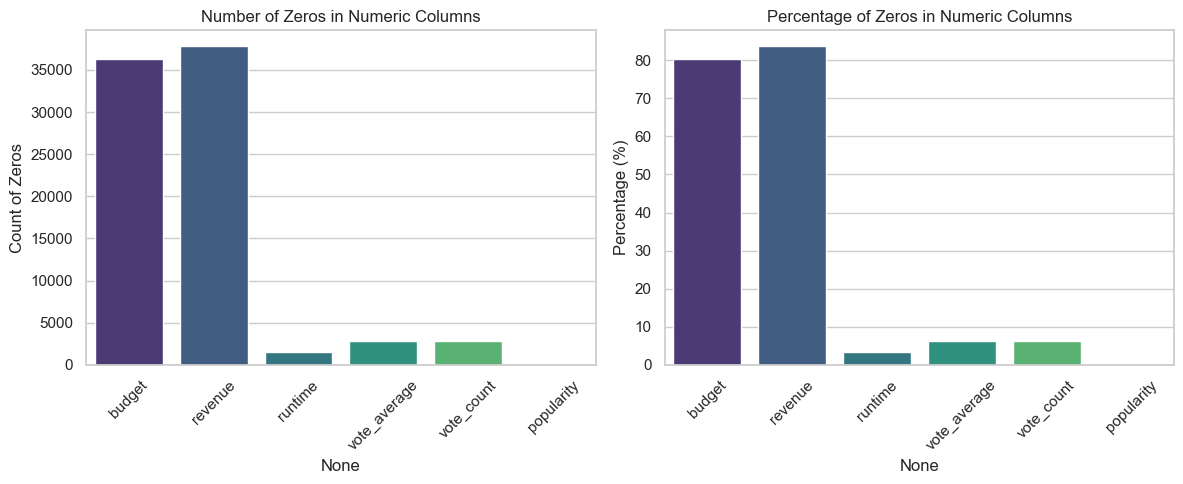

In [14]:
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
sns.barplot(x=zero_counts.index, y=zero_counts.values, palette="viridis")
plt.title("Number of Zeros in Numeric Columns")
plt.xticks(rotation=45)
plt.ylabel("Count of Zeros")

plt.subplot(1, 2, 2)
sns.barplot(x=zero_percent.index, y=zero_percent.values, palette="viridis")
plt.title("Percentage of Zeros in Numeric Columns")
plt.xticks(rotation=45)
plt.ylabel("Percentage (%)")

plt.tight_layout()
plt.show()

Therefore, considering the number of zeros, removing the problem and the existence of zero columns does not mean it is real and is a type of missing data.

- taking logarithms

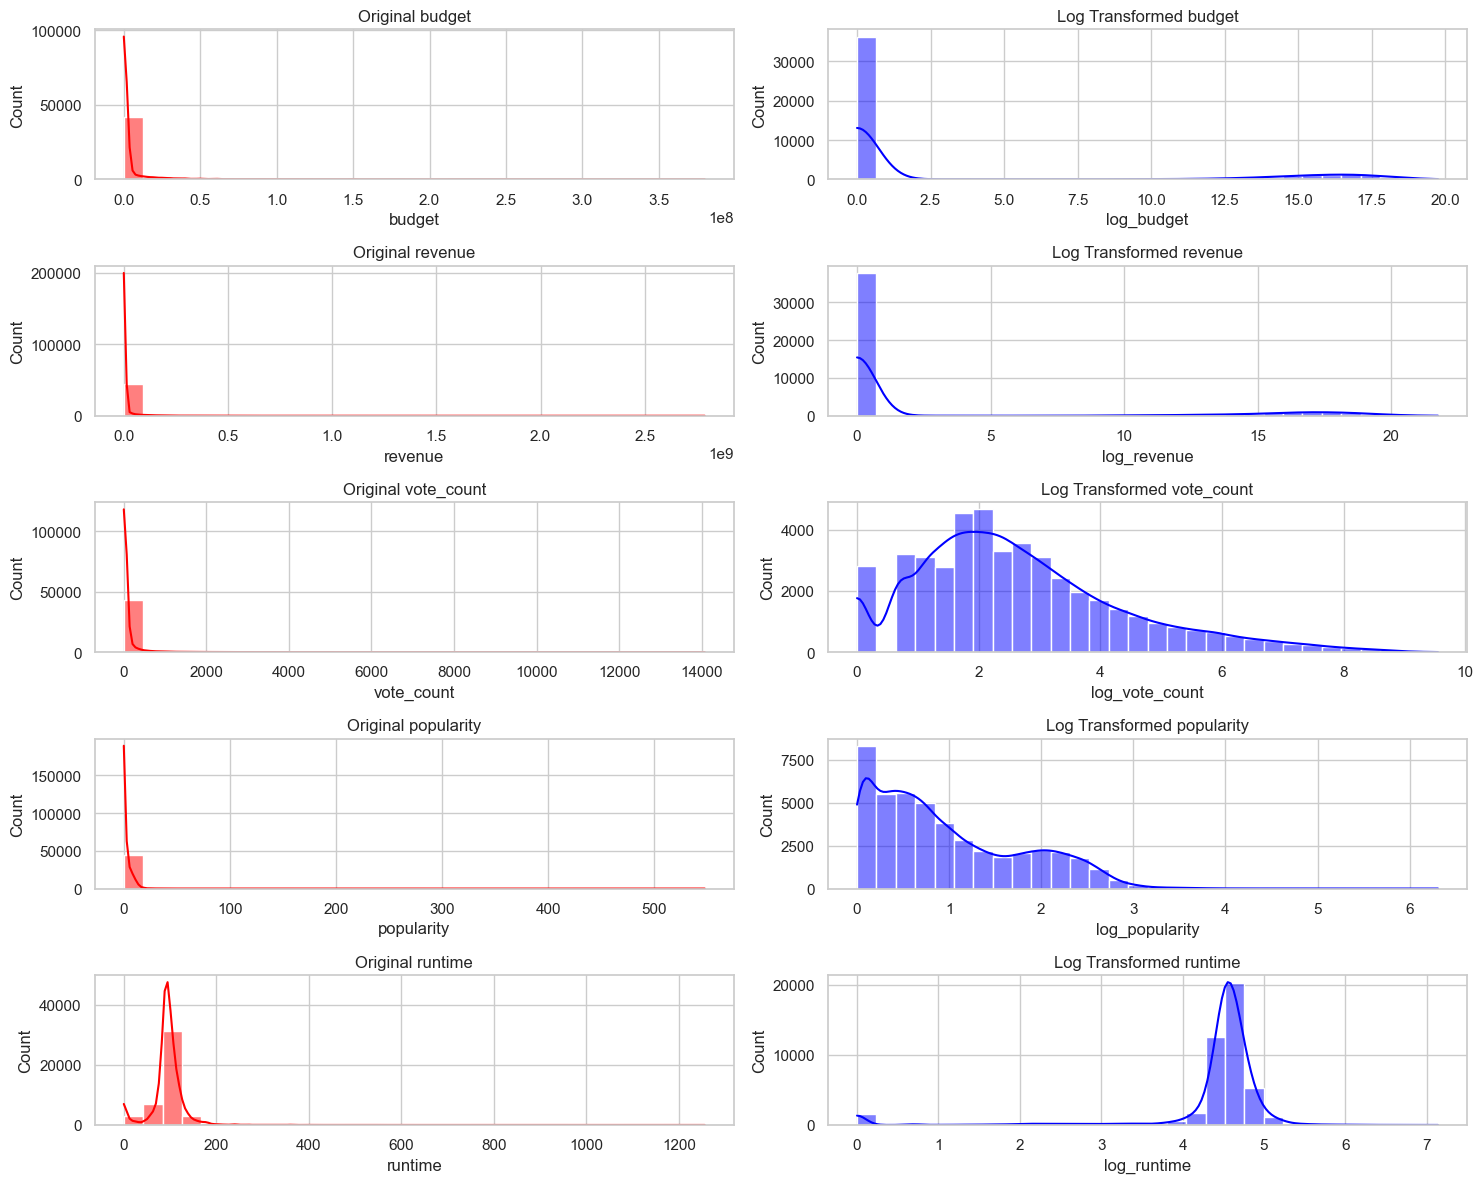

In [15]:

skewed_numeric_cols = ['budget', 'revenue', 'vote_count', 'popularity','runtime']
# log
for col in skewed_numeric_cols:
    df_log[f'log_{col}'] = np.log1p(df_log[col])


plt.figure(figsize=(15, 12))

for i, col in enumerate(skewed_numeric_cols):
    plt.subplot(5, 2, 2*i + 1)   # row=5, col=2
    sns.histplot(df_log[col], bins=30, kde=True, color='red')
    plt.title(f'Original {col}')

    plt.subplot(5, 2, 2*i + 2)
    sns.histplot(df_log[f'log_{col}'], bins=30, kde=True, color='blue')
    plt.title(f'Log Transformed {col}')

plt.tight_layout()
plt.show()





- second solution: : check for filling

In [16]:

cols = ['budget','revenue','vote_average','runtime','popularity']

for col in cols:
    df_missing[col] = df_missing[col].replace(0, np.nan)


In [17]:
missing_percent = df_missing[cols].isnull().mean() * 100

print(missing_percent)


budget          80.351848
revenue         83.624696
vote_average     6.412923
runtime          3.447665
popularity       0.132773
dtype: float64


<Figure size 800x400 with 0 Axes>

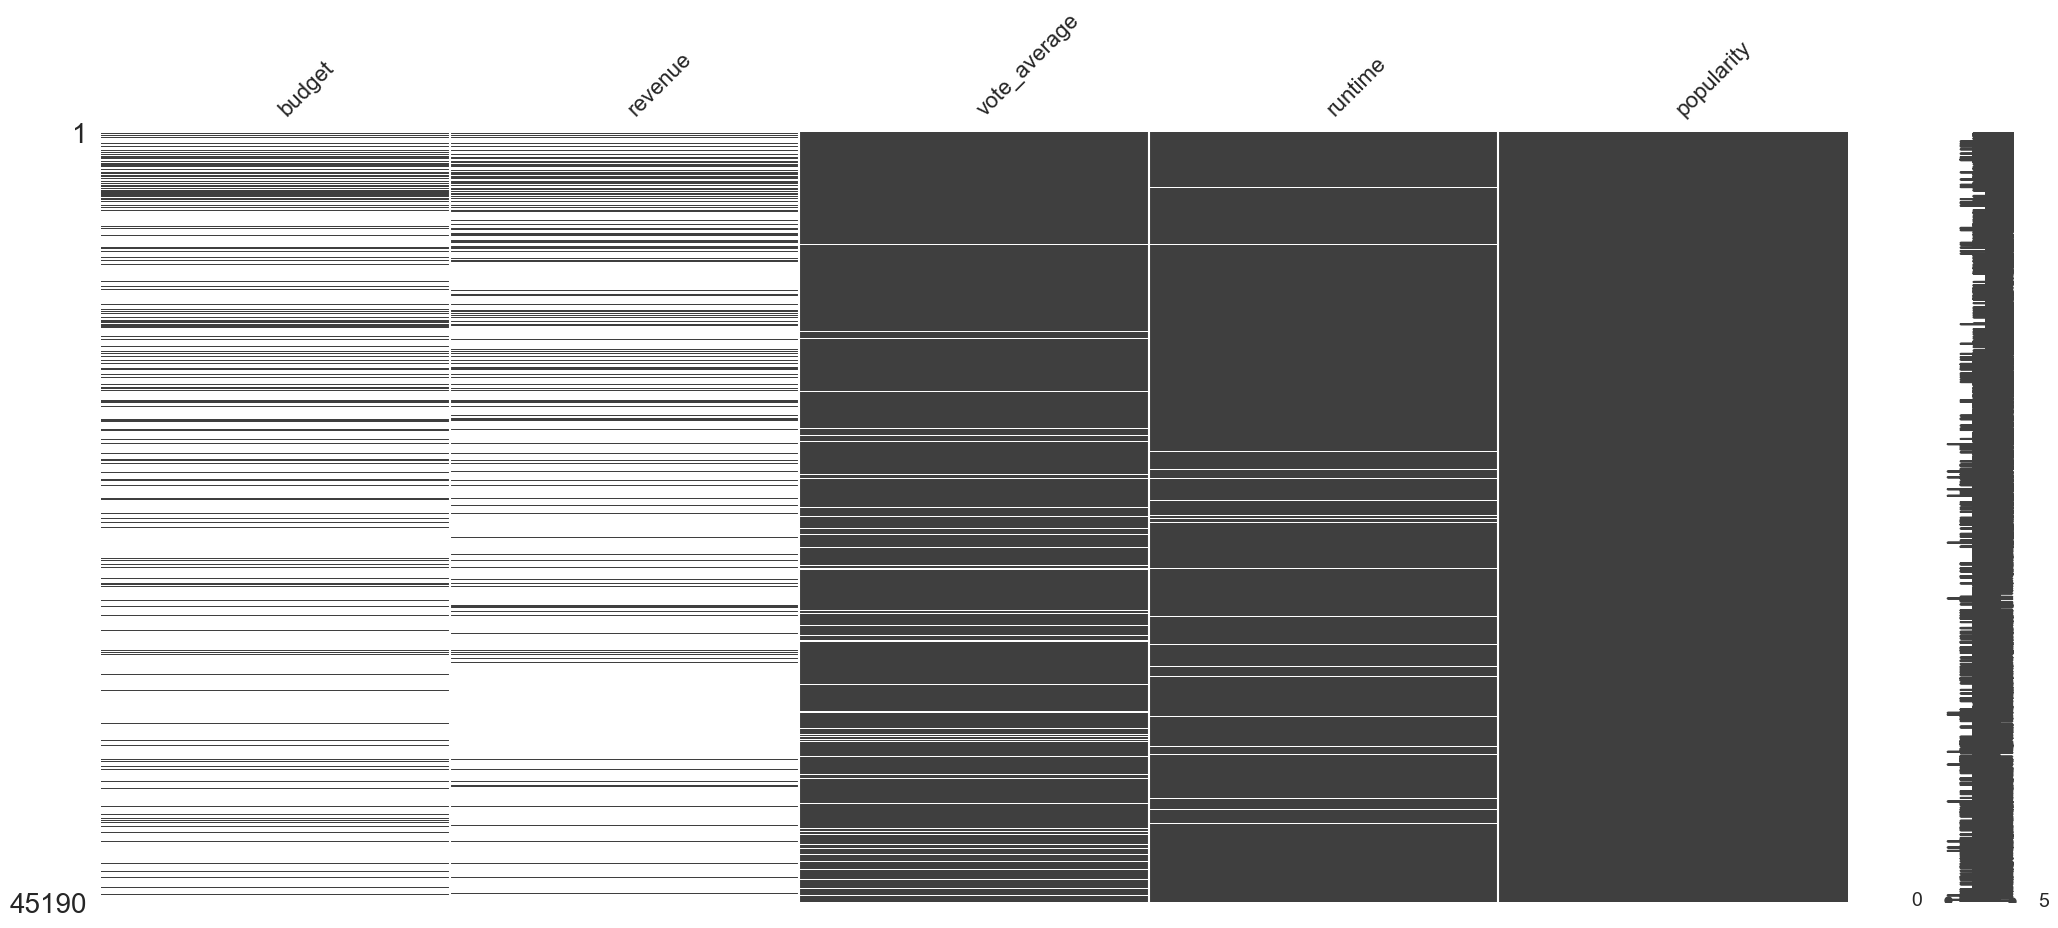

In [18]:


plt.figure(figsize=(8,4))
msno.matrix(df_missing[cols])

plt.show()


<Figure size 600x400 with 0 Axes>

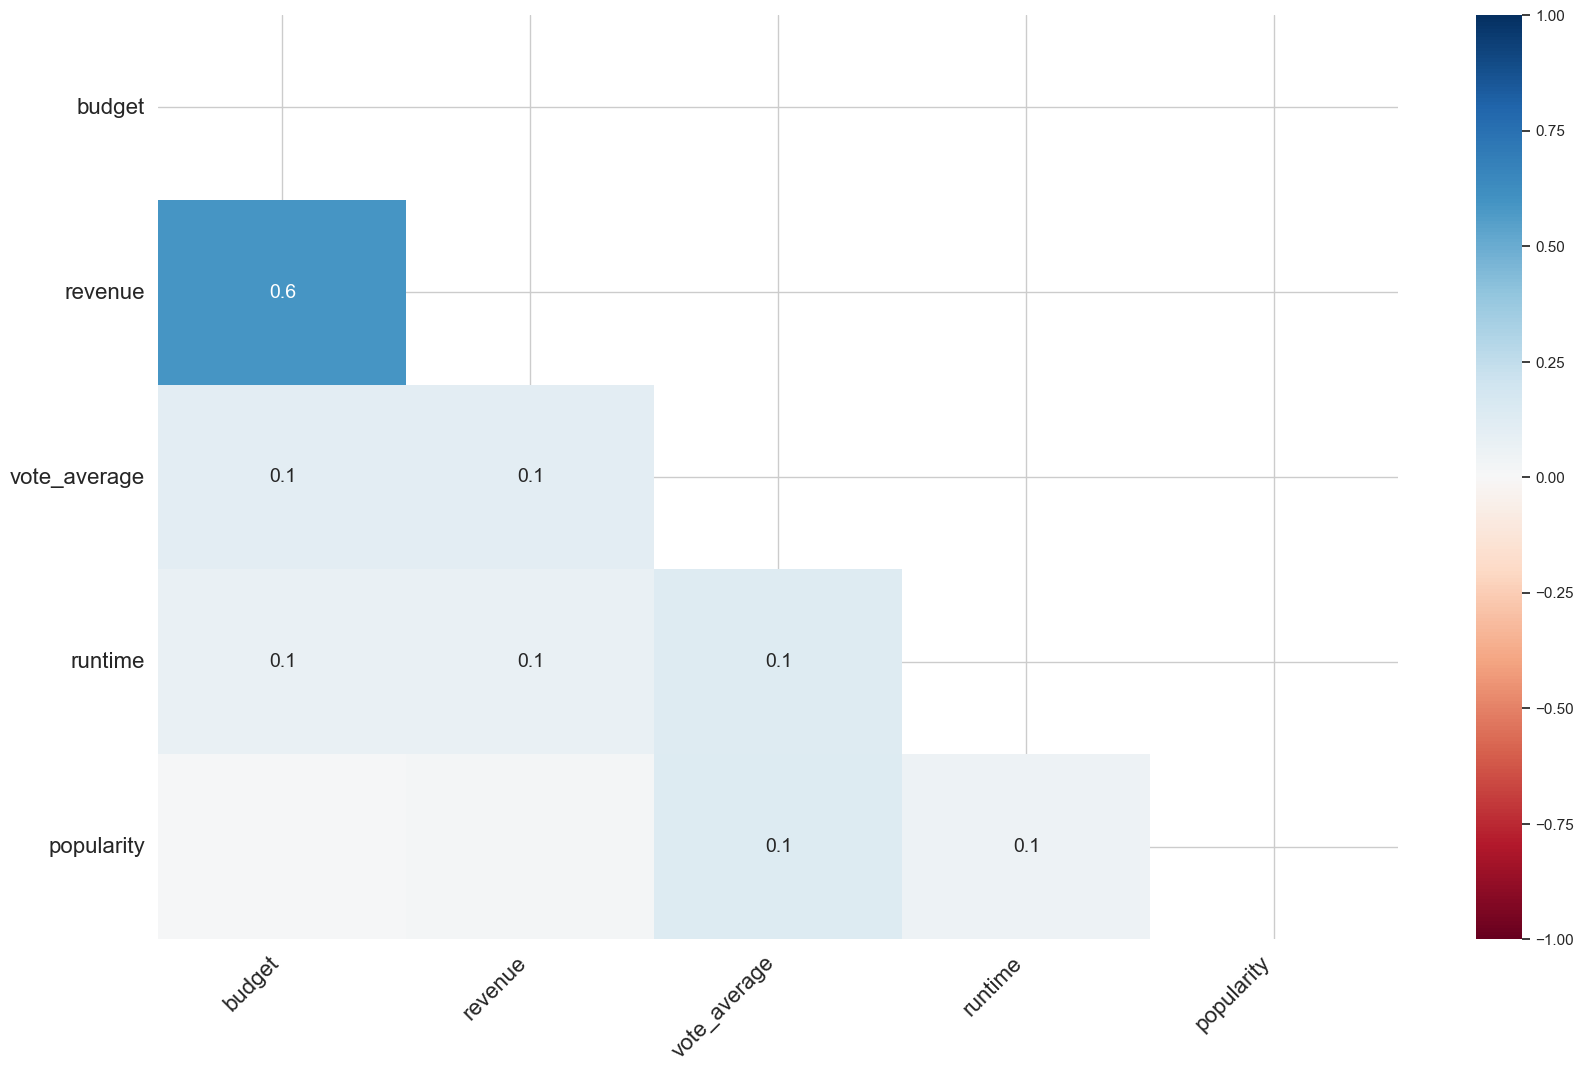

In [19]:
plt.figure(figsize=(6,4))

msno.heatmap(df_missing[cols])

plt.show()


In [20]:
from pyampute.exploration.mcar_statistical_tests import MCARTest

mcar_test = MCARTest()

p_value = mcar_test.little_mcar_test(df_missing[cols])

print("\nLittle MCAR Test p-value:", p_value)



Little MCAR Test p-value: 1.0


In [ ]:
df_missing['budget'] = df_missing['budget'].replace(0, np.nan)
df_missing['budget_missing'] = df_missing['budget'].isna().astype(int)
df_missing['budget'] = df_missing['budget'].fillna(df_missing['budget'].median())

df_missing['revenue'] = df_missing['revenue'].replace(0, np.nan)
df_missing['revenue_missing'] = df_missing['revenue'].isna().astype(int)
df_missing['revenue'] = df_missing['revenue'].fillna(df_missing['revenue'].median())

df_missing['vote_average'] = df_missing['vote_average'].replace(0, np.nan)
df_missing['vote_average_missing'] = df_missing['vote_average'].isna().astype(int)
df_missing['vote_average'] = df_missing['vote_average'].fillna(df_missing['vote_average'].median())

df_missing['runtime'] = df_missing['runtime'].replace(0, np.nan)
df_missing['runtime_missing'] = df_missing['runtime'].isna().astype(int)
df_missing['runtime'] = df_missing['runtime'].fillna(df_missing['runtime'].median())

df_missing['popularity'] = df_missing['popularity'].replace(0, np.nan)
df_missing['popularity_missing'] = df_missing['popularity'].isna().astype(int)
df_missing['popularity'] = df_missing['popularity'].fillna(df_missing['popularity'].median())


combine

In [22]:
df_missing['log_budget'] = np.log1p(df_missing['budget'])
df_missing['log_revenue'] = np.log1p(df_missing['revenue'])
df_missing["runtime_winsor"] = winsorize(df_missing["runtime"], limits=[0,0.01])
df_missing['log_popularity'] = np.log1p(df_missing['popularity'])


Text(0.5, 1.0, 'runtime_winsor winsor ')

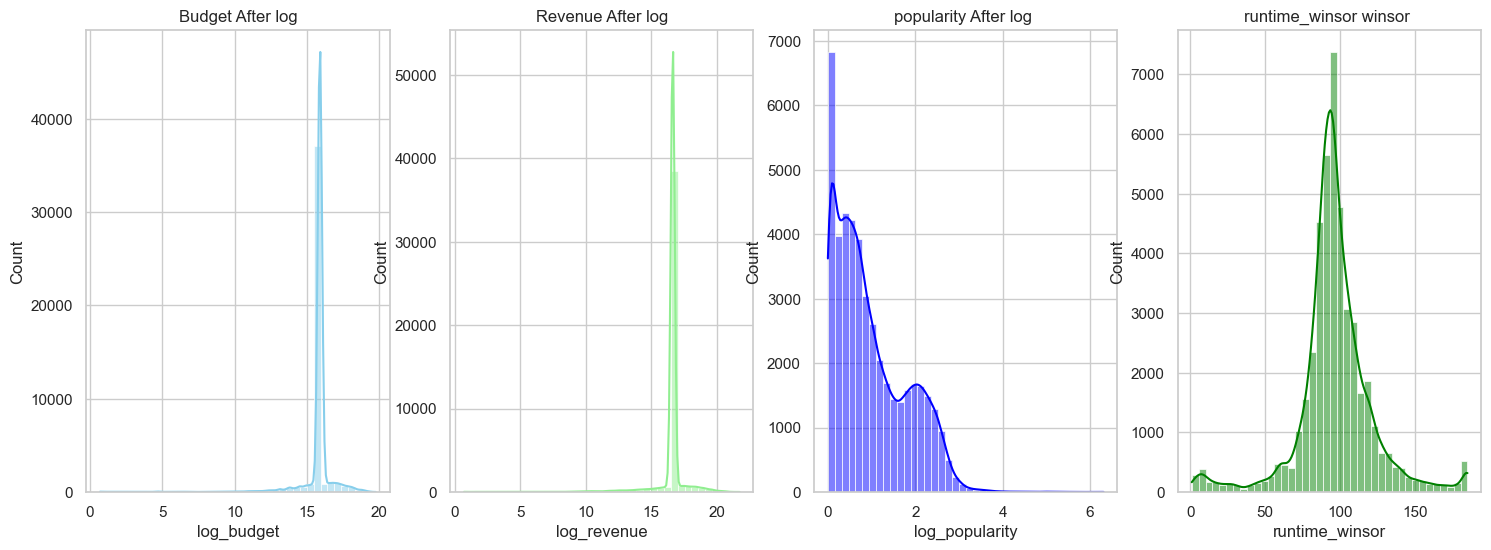

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

sns.histplot(df_missing['log_budget'], bins=40, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Budget After log")

sns.histplot(df_missing['log_revenue'], bins=40, kde=True, ax=axes[1], color='lightgreen')
axes[1].set_title("Revenue After log")

sns.histplot(df_missing['log_popularity'], bins=40, kde=True, ax=axes[2], color='blue')
axes[2].set_title("popularity After log ")

sns.histplot(df_missing['runtime_winsor'], bins=40, kde=True, ax=axes[3], color='green')
axes[3].set_title("runtime_winsor winsor ")


# Clustering Analysis

In the clustering section, these features are used depending on the problem: budget,runtime, and vote_average.

k=2, Inertia=106980.72, Silhouette Score=0.277
k=3, Inertia=81624.02, Silhouette Score=0.277
k=4, Inertia=65850.54, Silhouette Score=0.289
k=5, Inertia=54518.48, Silhouette Score=0.343
k=6, Inertia=47140.52, Silhouette Score=0.357
k=7, Inertia=40007.01, Silhouette Score=0.311
k=8, Inertia=35469.75, Silhouette Score=0.334
k=9, Inertia=31525.15, Silhouette Score=0.332
k=10, Inertia=28399.68, Silhouette Score=0.315


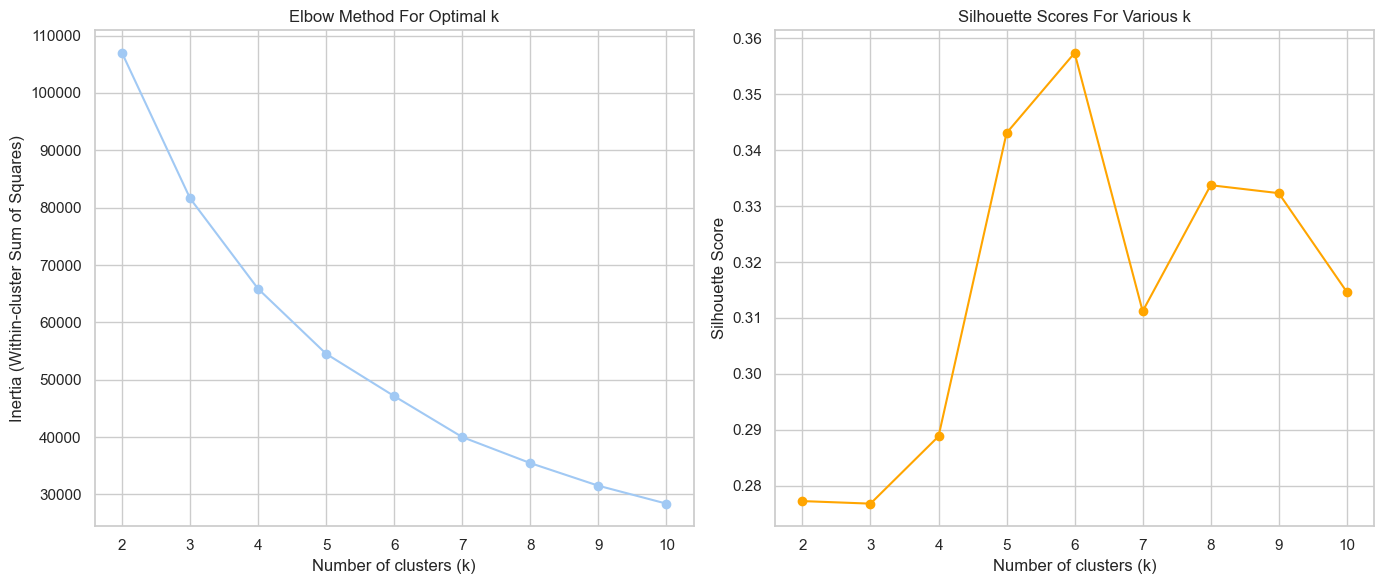

In [25]:

df_cluster = df_raw[['budget','vote_average','runtime']].copy()

df_cluster[['budget']] = df_cluster[['budget']].replace(0, np.nan)
df_cluster['budget'] = df_cluster['budget'].fillna(df_cluster['budget'].median())
df_cluster['log_budget'] = np.log1p(df_cluster['budget'])

df_cluster[['vote_average']] = df_cluster[['vote_average']].replace(0, np.nan)
df_cluster['vote_average'] = df_cluster['vote_average'].fillna(df_cluster['vote_average'].median())

df_cluster[['runtime']] = df_cluster[['runtime']].replace(0, np.nan)
df_cluster['runtime'] = df_cluster['runtime'].fillna(df_cluster['runtime'].median())

df_cluster['runtime_winsor'] = winsorize(
    df_cluster['runtime'],
    limits=[0, 0.005]
).data

from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(df_cluster[['log_budget','runtime_winsor','vote_average']])


ks = range(2, 11)
inertias = []
silhouette_scores = []

for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_avg = silhouette_score(X_scaled, labels)
    silhouette_scores.append(silhouette_avg)
    print(f'k={k}, Inertia={kmeans.inertia_:.2f}, Silhouette Score={silhouette_avg:.3f}')

plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.plot(ks, inertias, marker='o')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (Within-cluster Sum of Squares)')

plt.subplot(1,2,2)
plt.plot(ks, silhouette_scores, marker='o', color='orange')
plt.title('Silhouette Scores For Various k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()



In [26]:
# final kmeans
kmeans_final = KMeans(n_clusters=5, random_state=42)
df_cluster['cluster_label'] = kmeans_final.fit_predict(X_scaled)

df_cluster[['log_budget', 'runtime_winsor', 'vote_average', 'cluster_label']].head()


,log_budget,runtime_winsor,vote_average,cluster_label
0,17.216708,81.0,7.7,0
1,17.989898,104.0,6.9,0
2,15.894952,101.0,6.5,0
3,16.588099,127.0,6.1,4
4,15.894952,106.0,5.7,0


In [27]:
df_cluster['cluster_label'].value_counts()


cluster_label
0    24527
3    13140
4     4211
2     2717
1      595
Name: count, dtype: int64

In [28]:
df_cluster.groupby('cluster_label')[['log_budget', 'runtime_winsor', 'vote_average']].mean().round(2)


,log_budget,runtime_winsor,vote_average
cluster_label,,,
0,15.87,96.86,6.59
1,7.57,86.70,5.90
2,15.83,34.16,6.58
3,15.85,93.09,4.63
4,16.29,149.56,6.66


In [29]:
df_cluster.to_csv("df_cluster_final.csv", index=False)
df_cluster.to_pickle("df_cluster_final.pkl")
import joblib
joblib.dump(kmeans_final, "kmeans_final_model.pkl")


['kmeans_final_model.pkl']

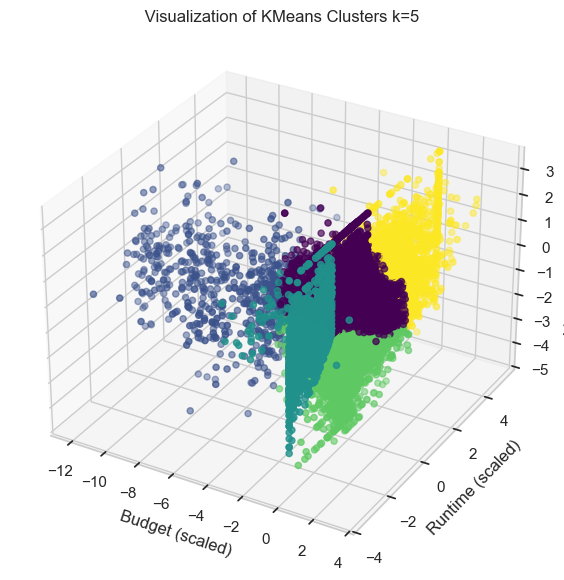

In [30]:


fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_scaled[:,0], X_scaled[:,1], X_scaled[:,2],
    c=df_cluster['cluster_label'], cmap='viridis'
)

ax.set_xlabel("Budget (scaled)")
ax.set_ylabel("Runtime (scaled)")
ax.set_zlabel("Vote Average (scaled)")
plt.title(" Visualization of KMeans Clusters k=5")
plt.show()


k=2
Inertia (from KMeans) = 106976.16
Silhouette (Hierarchical) = 0.2891
k=3
Inertia (from KMeans) = 81624.02
Silhouette (Hierarchical) = 0.2875
k=4
Inertia (from KMeans) = 65850.54
Silhouette (Hierarchical) = 0.2882
k=5
Inertia (from KMeans) = 54517.23
Silhouette (Hierarchical) = 0.3118
k=6
Inertia (from KMeans) = 47138.18
Silhouette (Hierarchical) = 0.3179
k=7
Inertia (from KMeans) = 40006.85
Silhouette (Hierarchical) = 0.3279
k=8
Inertia (from KMeans) = 35295.74
Silhouette (Hierarchical) = 0.2723
k=9
Inertia (from KMeans) = 31525.15
Silhouette (Hierarchical) = 0.2420
k=10
Inertia (from KMeans) = 28398.77
Silhouette (Hierarchical) = 0.2532


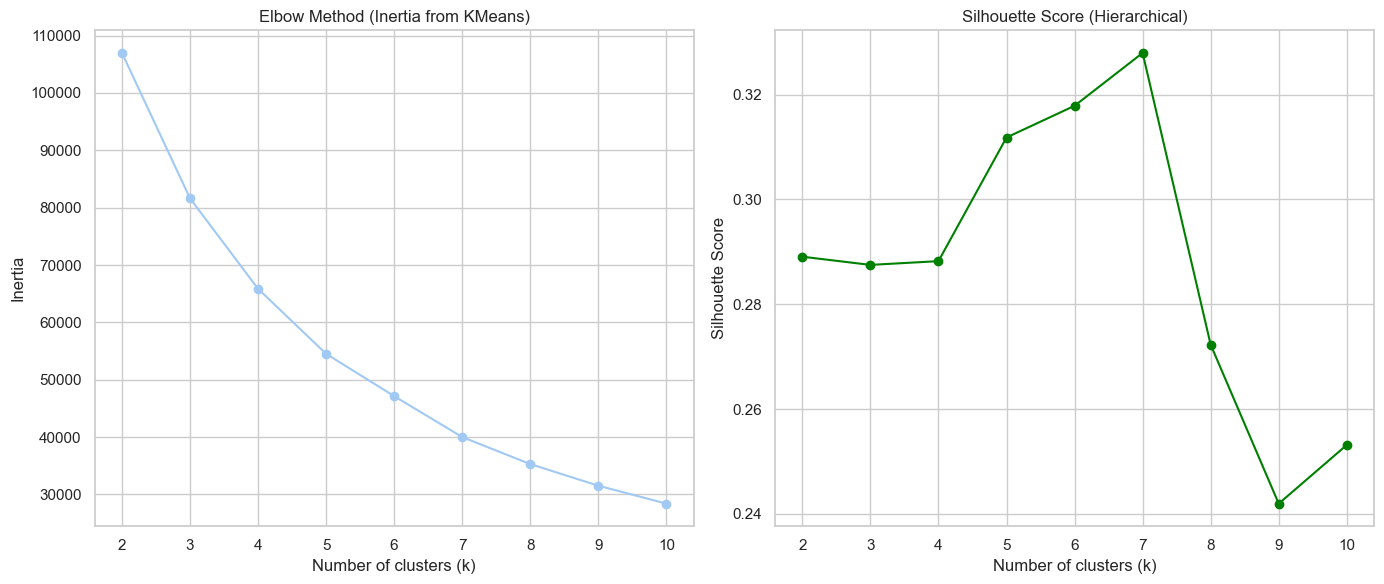

In [31]:
df_cluster = df_raw[['budget','vote_average','runtime']].copy()

df_cluster[['budget']] = df_cluster[['budget']].replace(0, np.nan)
df_cluster['budget'] = df_cluster['budget'].fillna(df_cluster['budget'].median())
df_cluster['log_budget'] = np.log1p(df_cluster['budget'])

df_cluster[['vote_average']] = df_cluster[['vote_average']].replace(0, np.nan)
df_cluster['vote_average'] = df_cluster['vote_average'].fillna(df_cluster['vote_average'].median())

df_cluster[['runtime']] = df_cluster[['runtime']].replace(0, np.nan)
df_cluster['runtime'] = df_cluster['runtime'].fillna(df_cluster['runtime'].median())

df_cluster['runtime_winsor'] = winsorize(
    df_cluster['runtime'],
    limits=[0, 0.005]
).data

X_scaled = StandardScaler().fit_transform(df_cluster[['log_budget','runtime_winsor','vote_average']])



inertias = []              
silhouette_scores = []    

for k in ks:

    hierarchical = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'   
    )

    labels_hier = hierarchical.fit_predict(X_scaled)

    sil_score = silhouette_score(X_scaled, labels_hier, metric='euclidean')
    silhouette_scores.append(sil_score)

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

    print(f'k={k}')
    print(f'Inertia (from KMeans) = {kmeans.inertia_:.2f}')
    print(f'Silhouette (Hierarchical) = {sil_score:.4f}')


plt.figure(figsize=(14,6))

# Elbow (Inertia from KMeans)
plt.subplot(1,2,1)
plt.plot(ks, inertias, marker='o')
plt.title('Elbow Method (Inertia from KMeans)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')

# Silhouette (Hierarchical)
plt.subplot(1,2,2)
plt.plot(ks, silhouette_scores, marker='o', color='green')
plt.title('Silhouette Score (Hierarchical)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()



In [40]:
final_hier = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

df_cluster['cluster'] = final_hier.fit_predict(X_scaled)


In [ ]:
# experiment with k=5
df_cluster['cluster'].value_counts()


cluster
2    27847
1    11727
3     2650
4     1619
0     1347
Name: count, dtype: int64

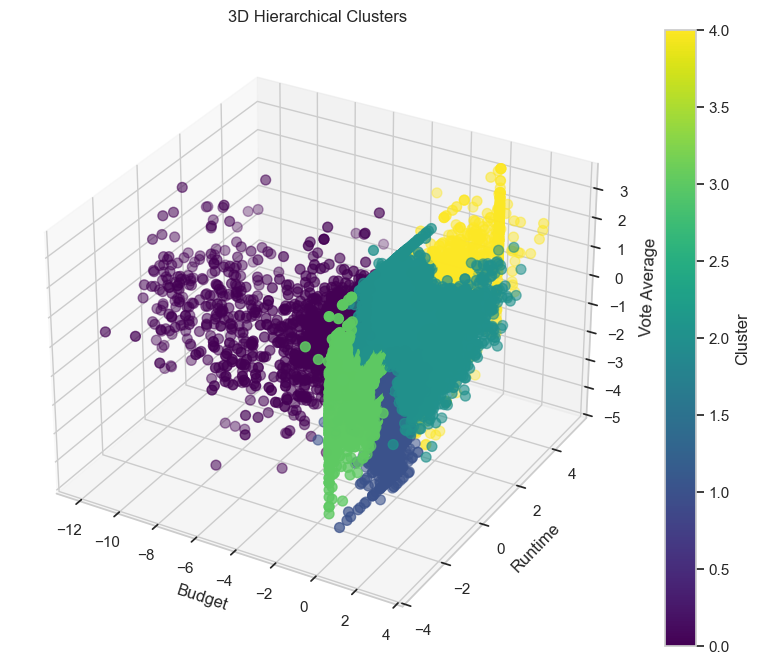

In [33]:

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_scaled[:,0],   
    X_scaled[:,1],   
    X_scaled[:,2],   
    c=df_cluster['cluster'],
    cmap='viridis',
    s=50
)
ax.set_xlabel('Budget')
ax.set_ylabel('Runtime')
ax.set_zlabel('Vote Average')

ax.set_title('3D Hierarchical Clusters')
plt.colorbar(scatter, label='Cluster')

plt.show()


#  Neural Network for Revenue Prediction

In [179]:
df_features = pd.read_csv("movies_metadata.csv")
df_features.head()

C:\Users\HHC\AppData\Local\Temp\ipykernel_24116\1895559625.py:1: DtypeWarning: Columns (0: popularity) have mixed types. Specify dtype option on import or set low_memory=False.
  df_features = pd.read_csv("movies_metadata.csv")


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


In [180]:
# duplicates
print("before:", df_features.duplicated().sum())
df_features = df_features.drop_duplicates()
print("after:", df_features.duplicated().sum())


before: 13
after: 0


In [181]:
df_features['revenue'] = pd.to_numeric(df_features['revenue'], errors='coerce')

df_features = df_features.dropna(subset=['revenue'])
df_features['budget'] = df_features['budget'].replace(0, np.nan)

df_features = df_features.dropna(subset=['revenue'])

df_features['log_revenue'] = np.log1p(df_features['revenue'])



In [182]:
df_features['adult'] = df_features['adult'].astype(str).str.lower()

df_features['adult_binary'] = df_features['adult'].map({
    'true': 1,
    'false': 0
})
print(df_features['adult_binary'].value_counts(dropna=False))


adult_binary
0    45438
1        9
Name: count, dtype: int64


In [183]:
#adult_binary
df_features = df_features.dropna(subset=['adult_binary'])
print(df_features['adult_binary'].value_counts(dropna=False))


adult_binary
0    45438
1        9
Name: count, dtype: int64


In [184]:
# has_collection
df_features['has_collection'] = df_features['belongs_to_collection'].notna().astype(int)
print(df_features['has_collection'].value_counts())


has_collection
0    40957
1     4490
Name: count, dtype: int64


In [185]:
import ast

df_features['genres'] = df_features['genres'].apply(
    lambda x: ast.literal_eval(x) if pd.notnull(x) else []
)

In [186]:
df_features['genres'].head(10)


0    [{'id': 16, 'name': 'Animation'}, {'id': 35, '...
1    [{'id': 12, 'name': 'Adventure'}, {'id': 14, '...
2    [{'id': 10749, 'name': 'Romance'}, {'id': 35, ...
3    [{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...
4                       [{'id': 35, 'name': 'Comedy'}]
5    [{'id': 28, 'name': 'Action'}, {'id': 80, 'nam...
6    [{'id': 35, 'name': 'Comedy'}, {'id': 10749, '...
7    [{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...
8    [{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...
9    [{'id': 12, 'name': 'Adventure'}, {'id': 28, '...
Name: genres, dtype: object

In [187]:
df_features['genres_list'] = df_features['genres'].apply(
    lambda x: [i['name'] for i in x]
)


In [188]:
df_features['genres_list'].head(10)


0           [Animation, Comedy, Family]
1          [Adventure, Fantasy, Family]
2                     [Romance, Comedy]
3              [Comedy, Drama, Romance]
4                              [Comedy]
5      [Action, Crime, Drama, Thriller]
6                     [Comedy, Romance]
7    [Action, Adventure, Drama, Family]
8         [Action, Adventure, Thriller]
9         [Adventure, Action, Thriller]
Name: genres_list, dtype: object

In [189]:
genres_dummies = df_features['genres_list'].explode().str.get_dummies().groupby(level=0).sum()
genres_dummies.head(10)


,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,Foreign,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
6,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
7,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [190]:
#original_language
df_features['original_language'].value_counts().head(15)


original_language
en    32260
fr     2437
it     1529
ja     1349
de     1079
es      994
ru      826
hi      508
ko      444
zh      409
sv      384
pt      316
cn      313
fi      295
nl      248
Name: count, dtype: int64

In [191]:
top_languages = df_features['original_language'].value_counts().head(10).index


In [192]:
df_features['language_grouped'] = df_features['original_language'].apply(lambda x: x if x in top_languages else 'Other')


In [193]:
language_dummies = pd.get_dummies(df_features['language_grouped'], prefix='lang')


In [194]:
language_dummies.head()


,lang_Other,lang_de,lang_en,lang_es,lang_fr,lang_hi,lang_it,lang_ja,lang_ko,lang_ru,lang_zh
0,False,False,True,False,False,False,False,False,False,False,False
1,False,False,True,False,False,False,False,False,False,False,False
2,False,False,True,False,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,True,False,False,False,False,False,False,False,False


In [195]:
language_dummies = language_dummies.astype(int)



In [196]:
language_dummies.head()


,lang_Other,lang_de,lang_en,lang_es,lang_fr,lang_hi,lang_it,lang_ja,lang_ko,lang_ru,lang_zh
0,0,0,1,0,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,0


In [197]:
#release_date 
df_features['release_date'] = pd.to_datetime(df_features['release_date'], errors='coerce')
df_features['release_date'].head()

0   1995-10-30
1   1995-12-15
2   1995-12-22
3   1995-12-22
4   1995-02-10
Name: release_date, dtype: datetime64[us]

In [198]:
print(df_features['release_date'].value_counts())

release_date
2008-01-01    136
2009-01-01    121
2007-01-01    117
2005-01-01    111
2006-01-01    101
             ... 
1895-12-28      1
2000-04-30      1
1904-03-05      1
1991-05-13      1
1917-10-21      1
Name: count, Length: 17333, dtype: int64


In [199]:
print(df_features['release_date'].isna().sum())
print(df_features['release_date'].isna().mean())


84
0.0018483068189319427


In [200]:
df_features = df_features.dropna(subset=['release_date'])


In [201]:
df_features['release_year'] = df_features['release_date'].dt.year
df_features['release_month'] = df_features['release_date'].dt.month

df_features['release_month'].value_counts().sort_index()


release_month
1     5910
2     3029
3     3553
4     3453
5     3338
6     3152
7     2640
8     3394
9     4836
10    4613
11    3661
12    3784
Name: count, dtype: int64

In [202]:
df_features['release_year'].describe()
#ok

count    45363.000000
mean      1991.879638
std         24.057134
min       1874.000000
25%       1978.000000
50%       2001.000000
75%       2010.000000
max       2020.000000
Name: release_year, dtype: float64

In [203]:
def is_us(x):
    try:
        countries = ast.literal_eval(x)
        return int(any(c['iso_3166_1'] == 'US' for c in countries))
    except:
        return 0

df_features['is_US_production'] = df_features['production_countries'].apply(is_us)


In [204]:
df_features['is_US_production'].value_counts()

is_US_production
0    24219
1    21144
Name: count, dtype: int64

In [205]:
import ast

def parse_companies(x):
    try:
        return len(ast.literal_eval(x))
    except:
        return 0

df_features['num_production_companies'] = df_features['production_companies'].apply(parse_companies)


In [206]:
df_features['num_production_companies'].value_counts()

num_production_companies
1     16574
0     11793
2      7959
3      4714
4      1946
5       949
6       561
7       314
8       180
9       133
10       67
11       42
12       34
16       21
13       19
14       16
15        9
17        7
19        5
20        5
21        4
26        3
18        3
22        3
24        1
25        1
Name: count, dtype: int64

In [207]:
import ast

def count_languages(x):
    try:
        return len(ast.literal_eval(x))
    except:
        return 0

df_features['num_languages'] = df_features['spoken_languages'].apply(count_languages)


In [208]:
df_features['num_languages'].value_counts()


num_languages
1     33705
2      5369
0      3766
3      1704
4       550
5       178
6        62
7        14
8         6
9         5
10        1
12        1
19        1
13        1
Name: count, dtype: int64

In [209]:

df_features['vote_count'] = pd.to_numeric(df_features['vote_count'], errors='coerce')


In [210]:
df_features['vote_count'].value_counts()

vote_count
1.0       3241
2.0       3127
0.0       2848
3.0       2781
4.0       2478
          ... 
357.0        1
718.0        1
2083.0       1
2002.0       1
2712.0       1
Name: count, Length: 1820, dtype: int64

In [211]:
df_features['vote_count'].isna().sum()


np.int64(0)

In [212]:
df_features['vote_count'] = pd.to_numeric(df_features['vote_count'], errors='coerce')


df_features['log_vote_count'] = np.log1p(df_features['vote_count'])


In [213]:
df_features['log_vote_count'].value_counts()


log_vote_count
0.693147    3241
1.098612    3127
0.000000    2848
1.386294    2781
1.609438    2478
            ... 
5.880533       1
6.577861       1
7.642044       1
7.602401       1
7.905810       1
Name: count, Length: 1820, dtype: int64

In [214]:
df_features['runtime'].isna().mean()


np.float64(0.005422921764433569)

In [215]:
df_features = df_features.dropna(subset=['runtime'])

In [216]:
df_features['runtime'].isna().mean()


np.float64(0.0)

In [217]:
df_features['runtime'] = df_features['runtime'].replace(0, np.nan)
df_features['runtime_missing'] = df_features['runtime'].isna().astype(int)
df_features['runtime'] = df_features['runtime'].fillna(df_features['runtime'].median())
df_features["runtime_winsor"] = winsorize(df_features["runtime"], limits=[0,0.01])


In [218]:
df_features['popularity'].isna().mean()


np.float64(0.0)

In [219]:
df_features['popularity'] = pd.to_numeric(df_features['popularity'], errors='coerce')


In [220]:
df_features['popularity'] = df_features['popularity'].replace(0, np.nan)
df_features['popularity_missing'] = df_features['popularity'].isna().astype(int)
df_features['popularity'] = df_features['popularity'].fillna(df_features['popularity'].median())
df_features['log_popularity'] = np.log1p(df_features['popularity'])



In [221]:
df_features['vote_average'].isna().mean()


np.float64(0.0)

In [222]:
df_features['vote_average'] = df_features['vote_average'].replace(0, np.nan)
df_features['vote_average_missing'] = df_features['vote_average'].isna().astype(int)
df_features['vote_average'] = df_features['vote_average'].fillna(df_features['vote_average'].median())


In [223]:
df_features['budget'] = pd.to_numeric(df_features['budget'], errors='coerce')

df_features = df_features.dropna(subset=['budget'])

In [224]:
df_features['budget'] = df_features['budget'].replace(0, np.nan)
df_features['budget_missing'] = df_features['budget'].isna().astype(int)
df_features['budget'] = df_features['budget'].fillna(df_features['budget'].median())


df_features['log_budget'] = np.log1p(df_features['budget'])



In [225]:
df_features['genre_count'] = df_features['genres_list'].apply(len)


In [226]:
df_features['budget_popularity_ratio'] = (
    df_features['log_budget'] * df_features['log_popularity']
)


In [227]:
model_features = [
    'log_budget',
    'log_vote_count',
    'has_collection',
    'log_popularity',
    'budget_missing',
    'is_US_production'

]



In [228]:
df_features = df_features.reset_index(drop=True)

genres_dummies = df_features['genres_list'].explode().str.get_dummies().groupby(level=0).sum()

top_genres = genres_dummies.sum().sort_values(ascending=False).head(10).index
genres_dummies = genres_dummies[top_genres]

language_dummies = pd.get_dummies(df_features['language_grouped'], prefix='lang')

genres_dummies = genres_dummies.reset_index(drop=True)
language_dummies = language_dummies.reset_index(drop=True)

X = pd.concat(
    [
        df_features[model_features],
        genres_dummies,
        language_dummies
    ],
    axis=1
)



In [229]:
y = df_features['log_revenue']


In [230]:
print(len(df_features))
print(len(genres_dummies))
print(len(language_dummies))


45117
45117
45117


In [231]:
X.isnull().sum().sum()


np.int64(0)

In [232]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)


In [233]:
print("Train size:", X_train.shape)
print("Validation size:", X_val.shape)
print("Test size:", X_test.shape)

Train size: (31581, 27)
Validation size: (6768, 27)
Test size: (6768, 27)


In [234]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()

model.add(Dense(64, activation='relu', input_dim=X_train_scaled.shape[1]))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='linear'))


c:\Users\HHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [236]:
model.compile(
    optimizer='adam',
    loss='mse'
)
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True
)
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop]
)


Epoch 1/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 16.0443 - val_loss: 14.4137
Epoch 2/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 14.1237 - val_loss: 14.2129
Epoch 3/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 13.9464 - val_loss: 14.1567
Epoch 4/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.8044 - val_loss: 14.1471
Epoch 5/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.7376 - val_loss: 14.0860
Epoch 6/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.6550 - val_loss: 14.3324
Epoch 7/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.5549 - val_loss: 14.0162
Epoch 8/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.4912 - val_loss: 14.1306
Epoch 9/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 13.4293 - val_loss: 14.0796
Epoch 10/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 13.3679 - val_loss: 14.1103
Epoch 11/100
987/987 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 13.2916 - val_loss: 14.1919
Epoch 12/100
987/98

In [237]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test MSE:", mse)
print("Test R2:", r2)


212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test MSE: 13.88859166423102
Test R2: 0.6210444656980694


In [238]:
df_features[model_features + ['log_revenue']].corr()['log_revenue'].sort_values(ascending=False)



log_revenue         1.000000
log_vote_count      0.640692
log_popularity      0.580887
is_US_production    0.274325
log_budget          0.192631
has_collection      0.175635
budget_missing     -0.616466
Name: log_revenue, dtype: float64